# 1. Persiapan env


In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

# Struktur repo: masukan dari data/clean/ dan data/raw/, keluaran ke data/hasil/.
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
CLEAN = ROOT / "data" / "clean"
RAW = ROOT / "data" / "raw"
HASIL = ROOT / "data" / "hasil"
GAMBAR = HASIL / "gambar_makalah"
GAMBAR.mkdir(parents=True, exist_ok=True)

# Biru dan oranye untuk dosis 1 dan dosis 2, abu-abu untuk pembanding.
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#b9b8b0"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#898781",
    "axes.labelcolor": INK2,
    "xtick.color": INK2,
    "ytick.color": INK2,
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})


def rapi(ax, sumbu="both"):
    # Garis bantu tipis di belakang data dan tanpa tanda kecil pada sumbu.
    ax.grid(axis=sumbu, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

## 2. Membaca data

Sel berikut membaca lima tabel:

* `asean_tahun.csv`: kasus, penduduk, cakupan MCV1 dan MCV2, serta PDB per kapita 11 negara ASEAN per tahun.
* `provinsi_2025.csv`: imunisasi campak balita di 38 provinsi.
* `tabel_padanan_provinsi.csv`: padanan nama provinsi antarsumber.
* `bps_penduduk_miskin_maret_2025.csv`: persentase penduduk miskin per provinsi dari BPS.
* `persentase-imunisasi-campak-balita-provinsi-2025.csv`: file BPS yang memuat angka imunisasi nasional. Tiga baris pertamanya berisi judul, jadi baris tersebut dilewati.

In [2]:
asean = pd.read_csv(CLEAN / "asean_tahun.csv")
provinsi = pd.read_csv(CLEAN / "provinsi_2025.csv", dtype={"kode_prov": str})
padanan = pd.read_csv(CLEAN / "tabel_padanan_provinsi.csv", dtype=str)
miskin = pd.read_csv(RAW / "bps_penduduk_miskin_maret_2025.csv")
imunisasi_bps = pd.read_csv(
    RAW / "persentase-imunisasi-campak-balita-provinsi-2025.csv",
    skiprows=3, header=None, names=["nama", "nilai"], encoding="utf-8-sig",
)

for nama, tabel in [("asean", asean), ("provinsi", provinsi), ("padanan", padanan), ("miskin", miskin), ("imunisasi_bps", imunisasi_bps)]:
    print(f"{nama}: {tabel.shape[0]} baris, {tabel.shape[1]} kolom")

asean: 110 baris, 9 kolom
provinsi: 38 baris, 6 kolom
padanan: 38 baris, 6 kolom
miskin: 39 baris, 2 kolom
imunisasi_bps: 39 baris, 2 kolom


## 3. Menggabungkan data kemiskinan

Nama provinsi pada tabel kemiskinan mengikuti penulisan BPS, misalnya `KEP. RIAU`, sehingga penggabungan dilakukan melalui tabel padanan. Baris `INDONESIA` dipisahkan sebagai angka nasional, lalu hasilnya diperiksa agar tetap 38 provinsi tanpa data kosong.

In [3]:
miskin_nasional = miskin.loc[miskin["provinsi"] == "INDONESIA", "persen_miskin_maret_2025"].iloc[0]

miskin_provinsi = miskin.rename(columns={"provinsi": "nama_bps"}).merge(padanan[["nama_bps", "provinsi"]], on="nama_bps")
provinsi = provinsi.merge(miskin_provinsi[["provinsi", "persen_miskin_maret_2025"]], on="provinsi", how="left")

assert len(provinsi) == 38
assert provinsi["persen_miskin_maret_2025"].notna().all()

print(f"Penduduk miskin nasional: {miskin_nasional}%")
display(provinsi.head())

Penduduk miskin nasional: 8.47%


,kode_prov,provinsi,tahun,imunisasi_campak_pct,kelompok,peringkat,persen_miskin_maret_2025
0,34,DI Yogyakarta,2025,83.42,>=70%,1,10.23
1,51,Bali,2025,79.62,>=70%,2,3.72
2,31,DKI Jakarta,2025,73.61,>=70%,3,4.28
3,33,Jawa Tengah,2025,72.61,>=70%,4,9.48
4,53,Nusa Tenggara Timur,2025,72.54,>=70%,5,18.60


## 4. Perkembangan kasus dan cakupan di Indonesia

Sel berikut mengambil data Indonesia untuk 2016 sampai 2025 dan menghitung *dropout rate*, yaitu selisih cakupan dosis 1 dan dosis 2 dibagi cakupan dosis 1. Angka ini hanya pendekatan karena kedua dosis dihitung dari kelompok sasaran yang berbeda. Data kasus baru tersedia sampai 2024.

In [4]:
asean["dropout_rate"] = (asean["mcv1_wuenic"] - asean["mcv2_wuenic"]) / asean["mcv1_wuenic"] * 100

indonesia = asean[(asean["iso3"] == "IDN") & (asean["tahun"] >= 2016)].sort_values("tahun").reset_index(drop=True)
indonesia_kasus = indonesia[indonesia["tahun"] <= 2024]

kolom_indonesia = ["tahun", "kasus_dilaporkan", "kasus_per_1juta", "mcv1_wuenic", "mcv2_wuenic", "dropout_rate"]
display(indonesia[kolom_indonesia].round(1))

,tahun,kasus_dilaporkan,kasus_per_1juta,mcv1_wuenic,mcv2_wuenic,dropout_rate
0,2016,6962.0,26.3,88.0,55.0,37.5
1,2017,9035.0,33.8,90.0,63.0,30.0
2,2018,5300.0,19.6,89.0,67.0,24.7
3,2019,1965.0,7.2,88.0,71.0,19.3
4,2020,524.0,1.9,76.0,60.0,21.1
5,2021,394.0,1.4,72.0,53.0,26.4
6,2022,7704.0,27.6,92.0,71.0,22.8
7,2023,18063.0,64.2,82.0,69.0,15.9
8,2024,6328.0,22.3,85.0,82.0,3.5
9,2025,NaN,NaN,85.0,78.0,8.2


## 5. Uji tren cakupan imunisasi

Sel berikut menguji tren cakupan 2016 sampai 2025 dengan regresi linear dan uji Mann-Kendall, yang di sini dihitung dengan Kendall tau antara tahun dan cakupan. Tren dianggap signifikan jika nilai p di bawah 0,05. Hasilnya menunjukkan dosis 2 cenderung naik, sedangkan dosis 1 tidak menunjukkan tren yang signifikan.

In [5]:
tahun = indonesia["tahun"].to_numpy(float)

baris_tren = []
for nama, kolom in [("Dosis 1 (MCV1)", "mcv1_wuenic"), ("Dosis 2 (MCV2)", "mcv2_wuenic")]:
    cakupan = indonesia[kolom].to_numpy(float)
    regresi = stats.linregress(tahun, cakupan)
    kendall = stats.kendalltau(tahun, cakupan)
    baris_tren.append({
        "dosis": nama,
        "kemiringan_poin_per_tahun": regresi.slope,
        "p_regresi": regresi.pvalue,
        "r2": regresi.rvalue ** 2,
        "tau_kendall": kendall.statistic,
        "p_kendall": kendall.pvalue,
    })

tren = pd.DataFrame(baris_tren)
display(tren.round(3))

,dosis,kemiringan_poin_per_tahun,p_regresi,r2,tau_kendall,p_kendall
0,Dosis 1 (MCV1),-0.539,0.475,0.066,-0.250,0.321
1,Dosis 2 (MCV2),2.079,0.033,0.453,0.494,0.048


## 6. Proyeksi dosis kedua

Sel berikut memperpanjang garis tren dosis 2 untuk memperkirakan tahun tercapainya target 90% *Immunization Agenda 2030* dan ambang 95%. Pita kepercayaan 95% dihitung agar ketidakpastiannya terlihat. Karena hanya memakai sepuluh titik data, hasil ini sebaiknya dibaca sebagai skenario.

In [6]:
mcv2 = indonesia["mcv2_wuenic"].to_numpy(float)
garis = stats.linregress(tahun, mcv2)

n_tahun = len(tahun)
galat = np.sqrt(((mcv2 - (garis.intercept + garis.slope * tahun)) ** 2).sum() / (n_tahun - 2))
sxx = ((tahun - tahun.mean()) ** 2).sum()
t_kritis = stats.t.ppf(0.975, n_tahun - 2)


def nilai_tren(th):
    # Mengembalikan batas bawah, nilai garis tren, dan batas atas pita kepercayaan 95%.
    tengah = garis.intercept + garis.slope * th
    lebar = t_kritis * galat * math.sqrt(1 / n_tahun + (th - tahun.mean()) ** 2 / sxx)
    return tengah - lebar, tengah, tengah + lebar


tahun_90 = (90 - garis.intercept) / garis.slope
tahun_95 = (95 - garis.intercept) / garis.slope
bawah_2030, tengah_2030, atas_2030 = nilai_tren(2030)
laju_90_2030 = (90 - nilai_tren(2025)[1]) / 5

print(f"Perkiraan mencapai 90%: {tahun_90:.1f}")
print(f"Perkiraan mencapai 95%: {tahun_95:.1f}")
print(f"Pita kepercayaan 2030: {bawah_2030:.1f}% sampai {min(atas_2030, 100):.1f}%")
print(f"Laju agar 90% tercapai pada 2030: {laju_90_2030:.2f} poin per tahun")

Perkiraan mencapai 90%: 2031.6
Perkiraan mencapai 95%: 2034.0
Pita kepercayaan 2030: 68.2% sampai 100.0%
Laju agar 90% tercapai pada 2030: 2.75 poin per tahun


## 7. Posisi Indonesia di ASEAN

Sel berikut menyusun perbandingan 11 negara ASEAN dan meregresikan cakupan dosis 2 terhadap logaritma PDB per kapita 2025. Hasil regresi memberi nilai harapan setiap negara pada tingkat pendapatannya, dan selisihnya menunjukkan negara yang berada di atas atau di bawah harapan. Kasus per 1 juta penduduk 2023 kosong untuk Singapura karena datanya tidak tersedia.

In [7]:
asean_2023 = asean[asean["tahun"] == 2023].set_index("iso3")
asean_2024 = asean[asean["tahun"] == 2024].set_index("iso3")
asean_2025 = asean[asean["tahun"] == 2025].set_index("iso3")

regresi_pdb = stats.linregress(np.log(asean_2025["pdb_per_kapita_usd"]), asean_2025["mcv2_wuenic"])
print(f"Regresi log PDB: R2 = {regresi_pdb.rvalue ** 2:.2f}, p = {regresi_pdb.pvalue:.3f}")

perbandingan = pd.DataFrame({
    "negara": asean_2025["negara"],
    "mcv1_2025": asean_2025["mcv1_wuenic"],
    "mcv2_2025": asean_2025["mcv2_wuenic"],
    "kasus_1juta_2023": asean_2023["kasus_per_1juta"],
    "kasus_1juta_2024": asean_2024["kasus_per_1juta"],
    "pdb_2025": asean_2025["pdb_per_kapita_usd"].round(0),
})
perbandingan["mcv2_harapan"] = (regresi_pdb.intercept + regresi_pdb.slope * np.log(asean_2025["pdb_per_kapita_usd"])).round(1)
perbandingan["selisih_harapan"] = (perbandingan["mcv2_2025"] - perbandingan["mcv2_harapan"]).round(1)
perbandingan["peringkat_mcv1"] = perbandingan["mcv1_2025"].rank(ascending=False, method="min").astype(int)
perbandingan["peringkat_mcv2"] = perbandingan["mcv2_2025"].rank(ascending=False, method="min").astype(int)
perbandingan["peringkat_pdb"] = perbandingan["pdb_2025"].rank(ascending=False, method="min").astype(int)

display(perbandingan.sort_values("mcv2_2025", ascending=False))

Regresi log PDB: R2 = 0.64, p = 0.003


,negara,mcv1_2025,mcv2_2025,kasus_1juta_2023,kasus_1juta_2024,pdb_2025,mcv2_harapan,selisih_harapan,peringkat_mcv1,peringkat_mcv2,peringkat_pdb
iso3,,,,,,,,,,,
BRN,Brunei,99.0,99.0,2.2,0.0,32235.0,92.9,6.1,1,1,2
VNM,Vietnam,98.0,95.0,0.4,77.8,5066.0,76.3,18.7,2,2,5
SGP,Singapura,97.0,93.0,NaN,2.0,98814.0,102.9,-9.9,3,3,1
THA,Thailand,93.0,87.0,0.9,114.4,8057.0,80.5,6.5,5,4,4
MYS,Malaysia,95.0,84.0,57.0,106.6,13125.0,84.9,-0.9,4,5,3
IDN,Indonesia,85.0,78.0,64.2,22.3,5060.0,76.3,1.7,7,6,6
KHM,Kamboja,87.0,73.0,0.6,37.8,2872.0,71.3,1.7,6,7,8
MMR,Myanmar,71.0,68.0,0.3,0.6,1489.0,65.4,2.6,9,8,10
PHL,Filipina,72.0,67.0,25.2,33.2,4171.0,74.6,-7.6,8,9,7


## 8. Sebaran imunisasi di 38 provinsi 

Sel berikut merangkum jumlah provinsi pada setiap kelompok capaian, menghitung provinsi di bawah angka nasional, dan menampilkan sepuluh provinsi terendah beserta persentase penduduk miskinnya. Angka nasional diambil dari baris `INDONESIA` pada file BPS.

In [8]:
imunisasi_nasional = imunisasi_bps.loc[imunisasi_bps["nama"] == "INDONESIA", "nilai"].iloc[0]

print(f"Imunisasi nasional: {imunisasi_nasional}%")
print(f"Provinsi di bawah angka nasional: {(provinsi['imunisasi_campak_pct'] < imunisasi_nasional).sum()}")
print(provinsi["kelompok"].value_counts().to_string())

terendah = provinsi.sort_values("imunisasi_campak_pct").head(10)
display(terendah[["provinsi", "imunisasi_campak_pct", "persen_miskin_maret_2025"]])

Imunisasi nasional: 63.52%
Provinsi di bawah angka nasional: 16
kelompok
50-70%    26
>=70%      8
<50%       4


,provinsi,imunisasi_campak_pct,persen_miskin_maret_2025
37,Aceh,27.79,12.33
36,Papua Pegunungan,36.69,30.03
35,Sumatera Barat,43.50,5.35
34,Papua Tengah,48.91,28.90
33,Riau,51.78,6.16
32,Sumatera Utara,53.25,7.36
31,Banten,55.35,5.63
30,Sulawesi Barat,57.79,10.41
29,Kalimantan Barat,58.84,6.16
28,Jambi,59.16,7.19


## 9. Uji normalitas

Sel berikut menjalankan uji Shapiro-Wilk pada setiap variabel yang dipakai dalam uji korelasi dan uji beda. Nilai p di bawah 0,05 berarti data menyimpang dari distribusi normal. PDB per kapita, kasus per 1 juta penduduk, imunisasi provinsi, dan penduduk miskin terbukti menyimpang. Variabel lainnya tidak terbukti menyimpang, tetapi jumlah datanya hanya 9 sampai 11 titik sehingga uji ini kurang peka. Karena itu, semua pasangan memakai koefisien Spearman dan uji beda memakai uji nonparametrik.

In [9]:
variabel_normalitas = {
    "Kasus, Indonesia 2016-2024": indonesia_kasus["kasus_dilaporkan"],
    "Dosis 1, Indonesia 2016-2024": indonesia_kasus["mcv1_wuenic"],
    "Dosis 2, Indonesia 2016-2024": indonesia_kasus["mcv2_wuenic"],
    "PDB per kapita, ASEAN 2025": asean_2025["pdb_per_kapita_usd"],
    "Kasus per 1 juta, ASEAN 2024": asean_2024["kasus_per_1juta"],
    "Dosis 1, ASEAN 2025": asean_2025["mcv1_wuenic"],
    "Dosis 2, ASEAN 2025": asean_2025["mcv2_wuenic"],
    "Imunisasi balita, 38 provinsi": provinsi["imunisasi_campak_pct"],
    "Penduduk miskin, 38 provinsi": provinsi["persen_miskin_maret_2025"],
}

normalitas = pd.DataFrame([
    {"variabel": nama, "p_shapiro": stats.shapiro(data).pvalue}
    for nama, data in variabel_normalitas.items()
])
normalitas["keputusan"] = np.where(normalitas["p_shapiro"] < 0.05, "Menyimpang dari normal", "Tidak terbukti menyimpang")
display(normalitas.round(4))

,variabel,p_shapiro,keputusan
0,"Kasus, Indonesia 2016-2024",0.1751,Tidak terbukti menyimpang
1,"Dosis 1, Indonesia 2016-2024",0.1723,Tidak terbukti menyimpang
2,"Dosis 2, Indonesia 2016-2024",0.8223,Tidak terbukti menyimpang
3,"PDB per kapita, ASEAN 2025",0.0000,Menyimpang dari normal
4,"Kasus per 1 juta, ASEAN 2024",0.0096,Menyimpang dari normal
5,"Dosis 1, ASEAN 2025",0.0856,Tidak terbukti menyimpang
6,"Dosis 2, ASEAN 2025",0.5729,Tidak terbukti menyimpang
7,"Imunisasi balita, 38 provinsi",0.0069,Menyimpang dari normal
8,"Penduduk miskin, 38 provinsi",0.0001,Menyimpang dari normal


## 10. Uji beda antarwilayah

Sel berikut membandingkan capaian provinsi dengan dua uji nonparametrik, sesuai hasil uji normalitas pada sel sebelumnya. Uji Mann-Whitney membandingkan Jawa-Bali dengan luar Jawa-Bali, sedangkan uji Kruskal-Wallis membandingkan tujuh wilayah. Wilayah ditentukan dari digit pertama kode provinsi, dan Bali dimasukkan ke kelompok Jawa-Bali. Hasilnya, capaian Jawa-Bali lebih tinggi secara signifikan, sedangkan perbedaan antartujuh wilayah tidak signifikan.

In [10]:
wilayah_kode = {
    "1": "Sumatera", "2": "Sumatera", "3": "Jawa", "5": "Bali-Nusa Tenggara",
    "6": "Kalimantan", "7": "Sulawesi", "8": "Maluku", "9": "Papua",
}
provinsi["wilayah"] = provinsi["kode_prov"].str[0].map(wilayah_kode)
jawa_bali = (provinsi["wilayah"] == "Jawa") | (provinsi["provinsi"] == "Bali")

mann_whitney = stats.mannwhitneyu(
    provinsi.loc[jawa_bali, "imunisasi_campak_pct"],
    provinsi.loc[~jawa_bali, "imunisasi_campak_pct"],
    alternative="two-sided",
)
kruskal = stats.kruskal(*[kelompok["imunisasi_campak_pct"] for _, kelompok in provinsi.groupby("wilayah")])

print(f"Median Jawa-Bali: {provinsi.loc[jawa_bali, 'imunisasi_campak_pct'].median():.1f}% (n = {jawa_bali.sum()})")
print(f"Median luar Jawa-Bali: {provinsi.loc[~jawa_bali, 'imunisasi_campak_pct'].median():.1f}% (n = {(~jawa_bali).sum()})")
print(f"Mann-Whitney: U = {mann_whitney.statistic:.1f}, p = {mann_whitney.pvalue:.3f}")
print(f"Kruskal-Wallis: H = {kruskal.statistic:.2f}, p = {kruskal.pvalue:.3f}")
display(provinsi.groupby("wilayah")["imunisasi_campak_pct"].median().round(1).sort_values().to_frame("median"))

Median Jawa-Bali: 72.6% (n = 7)
Median luar Jawa-Bali: 63.6% (n = 31)
Mann-Whitney: U = 168.0, p = 0.024
Kruskal-Wallis: H = 9.04, p = 0.171


,median
wilayah,
Sumatera,59.9
Kalimantan,60.7
Maluku,62.0
Papua,65.7
Sulawesi,66.0
Jawa,70.6
Bali-Nusa Tenggara,72.5


## 11. Fungsi uji korelasi Spearman

Sel berikut mendefinisikan fungsi yang menghitung koefisien Spearman, statistik t, nilai p, dan interval kepercayaan 95%. Interval dihitung dengan transformasi Fisher dan varians Bonett-Wright. Kekuatan hubungan mengikuti pengelompokan Schober dkk. (2018). Koefisien Pearson ikut dihitung sebagai pembanding.

In [11]:
def uji_spearman(x, y, nama, data):
    pasangan = pd.concat([x, y], axis=1).dropna()
    n = len(pasangan)
    a = pasangan.iloc[:, 0].to_numpy(float)
    b = pasangan.iloc[:, 1].to_numpy(float)

    rho, p = stats.spearmanr(a, b)
    statistik_t = rho * math.sqrt((n - 2) / (1 - rho ** 2))
    galat_baku = math.sqrt((1 + rho ** 2 / 2) / (n - 3))
    pearson = stats.pearsonr(a, b)

    nilai_mutlak = abs(rho)
    if nilai_mutlak < 0.10:
        kekuatan = "Dapat diabaikan"
    elif nilai_mutlak < 0.40:
        kekuatan = "Lemah"
    elif nilai_mutlak < 0.70:
        kekuatan = "Sedang"
    elif nilai_mutlak < 0.90:
        kekuatan = "Kuat"
    else:
        kekuatan = "Sangat kuat"

    return {
        "pasangan": nama,
        "data": data,
        "n": n,
        "rho": rho,
        "t": statistik_t,
        "p": p,
        "ik_bawah": math.tanh(math.atanh(rho) - 1.96 * galat_baku),
        "ik_atas": math.tanh(math.atanh(rho) + 1.96 * galat_baku),
        "kekuatan": kekuatan,
        "keputusan": "H0 ditolak" if p < 0.05 else "H0 gagal ditolak",
        "pearson_r": pearson[0],
        "pearson_p": pearson[1],
    }

## 12. Hasil uji korelasi 

Sel berikut menguji tujuh pasang variabel dengan uji dua sisi dan taraf signifikansi 0,05. H0 menyatakan tidak ada hubungan monotonik, sedangkan H1 menyatakan hubungan tersebut ada. PDB per kapita memakai data 2025 agar sama dengan *dashboard*, sedangkan kasus per 1 juta penduduk memakai 2024 karena data kasus baru sampai tahun tersebut. Hanya hubungan PDB per kapita dengan cakupan yang signifikan.

In [12]:
korelasi = pd.DataFrame([
    uji_spearman(indonesia_kasus["kasus_dilaporkan"], indonesia_kasus["mcv1_wuenic"], "Kasus dan dosis 1", "Indonesia 2016-2024"),
    uji_spearman(indonesia_kasus["kasus_dilaporkan"], indonesia_kasus["mcv2_wuenic"], "Kasus dan dosis 2", "Indonesia 2016-2024"),
    uji_spearman(asean_2025["pdb_per_kapita_usd"], asean_2025["mcv1_wuenic"], "PDB per kapita dan dosis 1", "ASEAN 2025"),
    uji_spearman(asean_2025["pdb_per_kapita_usd"], asean_2025["mcv2_wuenic"], "PDB per kapita dan dosis 2", "ASEAN 2025"),
    uji_spearman(asean_2024["kasus_per_1juta"], asean_2024["mcv1_wuenic"], "Kasus per 1 juta dan dosis 1", "ASEAN 2024"),
    uji_spearman(asean_2024["kasus_per_1juta"], asean_2024["mcv2_wuenic"], "Kasus per 1 juta dan dosis 2", "ASEAN 2024"),
    uji_spearman(provinsi["persen_miskin_maret_2025"], provinsi["imunisasi_campak_pct"], "Penduduk miskin dan imunisasi balita", "38 provinsi 2025"),
])

display(korelasi.drop(columns=["pearson_r", "pearson_p"]).round(3))

,pasangan,data,n,rho,t,p,ik_bawah,ik_atas,kekuatan,keputusan
0,Kasus dan dosis 1,Indonesia 2016-2024,9,0.527,1.641,0.145,-0.261,0.894,Sedang,H0 gagal ditolak
1,Kasus dan dosis 2,Indonesia 2016-2024,9,0.335,0.940,0.379,-0.442,0.824,Lemah,H0 gagal ditolak
2,PDB per kapita dan dosis 1,ASEAN 2025,11,0.873,5.363,0.000,0.485,0.974,Kuat,H0 ditolak
3,PDB per kapita dan dosis 2,ASEAN 2025,11,0.873,5.363,0.000,0.485,0.974,Kuat,H0 ditolak
4,Kasus per 1 juta dan dosis 1,ASEAN 2024,11,0.292,0.914,0.384,-0.386,0.765,Lemah,H0 gagal ditolak
5,Kasus per 1 juta dan dosis 2,ASEAN 2024,11,0.232,0.717,0.492,-0.435,0.735,Lemah,H0 gagal ditolak
6,Penduduk miskin dan imunisasi balita,38 provinsi 2025,38,-0.085,-0.515,0.610,-0.395,0.241,Dapat diabaikan,H0 gagal ditolak


## 13. Uji sensitivitas

Sel berikut memeriksa apakah hasil bergantung pada pilihan data. Korelasi kasus dan cakupan dihitung ulang tanpa 2020 dan 2021, korelasi PDB per kapita dihitung ulang dengan data 2024, dan korelasi kemiskinan dihitung ulang tanpa enam provinsi Papua. Pada data tanpa 2020 dan 2021, koefisiennya menjadi negatif, sehingga arah positif pada Tabel 3.6 dipengaruhi kedua tahun tersebut.

In [13]:
tanpa_pandemi = indonesia_kasus[~indonesia_kasus["tahun"].isin([2020, 2021])]
tanpa_papua = provinsi[~provinsi["provinsi"].str.contains("Papua")]

sensitivitas = pd.DataFrame([
    uji_spearman(tanpa_pandemi["kasus_dilaporkan"], tanpa_pandemi["mcv1_wuenic"], "Kasus dan dosis 1", "Tanpa 2020 dan 2021"),
    uji_spearman(tanpa_pandemi["kasus_dilaporkan"], tanpa_pandemi["mcv2_wuenic"], "Kasus dan dosis 2", "Tanpa 2020 dan 2021"),
    uji_spearman(asean_2024["pdb_per_kapita_usd"], asean_2024["mcv1_wuenic"], "PDB per kapita dan dosis 1", "ASEAN 2024"),
    uji_spearman(asean_2024["pdb_per_kapita_usd"], asean_2024["mcv2_wuenic"], "PDB per kapita dan dosis 2", "ASEAN 2024"),
    uji_spearman(tanpa_papua["persen_miskin_maret_2025"], tanpa_papua["imunisasi_campak_pct"], "Penduduk miskin dan imunisasi balita", "Tanpa enam provinsi Papua"),
])

display(sensitivitas[["pasangan", "data", "n", "rho", "p", "keputusan"]].round(3))

,pasangan,data,n,rho,p,keputusan
0,Kasus dan dosis 1,Tanpa 2020 dan 2021,7,-0.018,0.969,H0 gagal ditolak
1,Kasus dan dosis 2,Tanpa 2020 dan 2021,7,-0.288,0.531,H0 gagal ditolak
2,PDB per kapita dan dosis 1,ASEAN 2024,11,0.834,0.001,H0 ditolak
3,PDB per kapita dan dosis 2,ASEAN 2024,11,0.784,0.004,H0 ditolak
4,Penduduk miskin dan imunisasi balita,Tanpa enam provinsi Papua,32,-0.022,0.905,H0 gagal ditolak


## 14. Kasus dan cakupan imunisasi Indonesia

Sel berikut menggambar dua grafik garis. Grafik kiri menampilkan kasus yang dilaporkan 2016 sampai 2024, dan grafik kanan menampilkan cakupan kedua dosis 2016 sampai 2025 dengan garis ambang 95%. Area abu-abu menandai masa pandemi.

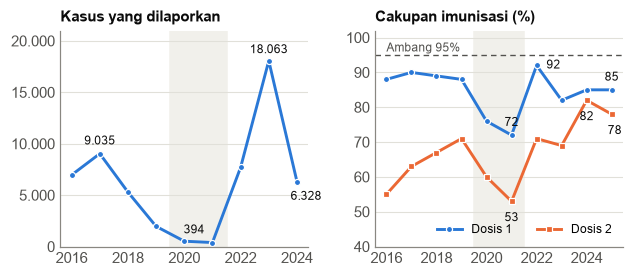

In [15]:
fig, (ax_kasus, ax_cakupan) = plt.subplots(1, 2, figsize=(6.6, 2.55), gridspec_kw={"wspace": 0.27})
for ax in (ax_kasus, ax_cakupan):
    ax.axvspan(2019.5, 2021.5, color="#f1f0eb", zorder=0)

# Grafik kasus
ax_kasus.plot(indonesia_kasus["tahun"], indonesia_kasus["kasus_dilaporkan"], color=BIRU, lw=1.9, marker="o", ms=4, mec="white", mew=0.8)
for th, geser_x, geser_y in [(2017, 0, 6), (2021, -12, 6), (2023, 0, 5), (2024, 6, -12)]:
    nilai = int(indonesia_kasus.loc[indonesia_kasus["tahun"] == th, "kasus_dilaporkan"].iloc[0])
    ax_kasus.annotate(f"{nilai:,}".replace(",", "."), (th, nilai), textcoords="offset points", xytext=(geser_x, geser_y), ha="center", fontsize=8, color=INK)
rapi(ax_kasus, "y")
ax_kasus.set_ylim(0, 21000)
ax_kasus.set_xticks(range(2016, 2025, 2))
ax_kasus.yaxis.set_major_formatter(lambda nilai, _: f"{int(nilai):,}".replace(",", "."))
ax_kasus.set_title("Kasus yang dilaporkan", loc="left", fontsize=9.5, fontweight="bold", color=INK)

# Grafik cakupan
ax_cakupan.axhline(95, color=INK2, lw=0.9, ls=(0, (4, 3)))
ax_cakupan.text(2016, 96, "Ambang 95%", fontsize=7.8, color=INK2)
ax_cakupan.plot(indonesia["tahun"], indonesia["mcv1_wuenic"], color=BIRU, lw=1.9, marker="o", ms=4, mec="white", mew=0.8, label="Dosis 1")
ax_cakupan.plot(indonesia["tahun"], indonesia["mcv2_wuenic"], color=ORANYE, lw=1.9, marker="s", ms=4, mec="white", mew=0.8, label="Dosis 2")
label_cakupan = [
    (2021, "mcv1_wuenic", 0, 6), (2022, "mcv1_wuenic", 11, -2), (2025, "mcv1_wuenic", 0, 6),
    (2021, "mcv2_wuenic", 0, -13), (2024, "mcv2_wuenic", 0, -13), (2025, "mcv2_wuenic", 2, -13),
]
for th, kolom, geser_x, geser_y in label_cakupan:
    nilai = indonesia.loc[indonesia["tahun"] == th, kolom].iloc[0]
    ax_cakupan.annotate(f"{int(nilai)}", (th, nilai), textcoords="offset points", xytext=(geser_x, geser_y), ha="center", fontsize=8, color=INK)
rapi(ax_cakupan, "y")
ax_cakupan.set_ylim(40, 102)
ax_cakupan.set_xticks(range(2016, 2026, 2))
ax_cakupan.legend(frameon=False, loc="lower right", fontsize=8, ncol=2)
ax_cakupan.set_title("Cakupan imunisasi (%)", loc="left", fontsize=9.5, fontweight="bold", color=INK)

fig.savefig(GAMBAR / "gambar_3_2_tren.png")
plt.show()

## 15. Cakupan dosis kedua di ASEAN

Sel berikut menggambar dua grafik sebar. Grafik kiri menghubungkan PDB per kapita dengan dosis 2 tahun 2025, dan grafik kanan menghubungkan kasus per 1 juta penduduk dengan dosis 2 tahun 2024. Kedua sumbu mendatar memakai skala logaritma karena rentang nilainya lebar, dan Indonesia diberi warna biru.

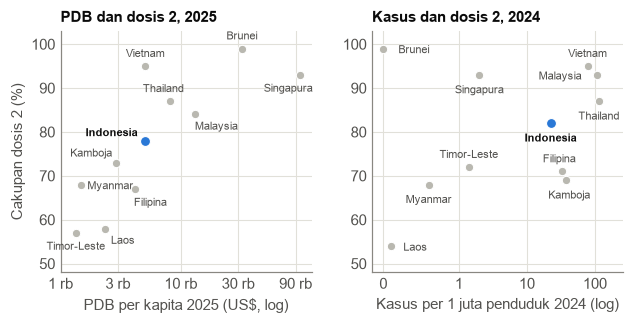

In [16]:
geser_pdb = {
    "BRN": (0, 6), "SGP": (-8, -11), "MYS": (14, -10), "THA": (-4, 6), "VNM": (0, 6), "IDN": (-22, 3),
    "KHM": (-16, 4), "MMR": (19, -3), "PHL": (10, -11), "LAO": (12, -10), "TLS": (0, -11),
}
geser_kasus = {
    "BRN": (20, -3), "SGP": (0, -12), "MYS": (-24, -3), "THA": (0, -12), "VNM": (0, 6), "IDN": (0, -12),
    "KHM": (2, -12), "MMR": (0, -12), "PHL": (-2, 6), "LAO": (16, -3), "TLS": (0, 6),
}

fig, (ax_pdb, ax_kasus) = plt.subplots(1, 2, figsize=(6.6, 2.85), gridspec_kw={"wspace": 0.24})
for ax, tabel, kolom, geser in [(ax_pdb, asean_2025, "pdb_per_kapita_usd", geser_pdb), (ax_kasus, asean_2024, "kasus_per_1juta", geser_kasus)]:
    for iso, baris in tabel.iterrows():
        adalah_indonesia = iso == "IDN"
        ax.scatter(baris[kolom], baris["mcv2_wuenic"], s=42 if adalah_indonesia else 30, color=BIRU if adalah_indonesia else ABU, edgecolor="white", linewidth=0.7, zorder=3)
        ax.annotate(baris["negara"], (baris[kolom], baris["mcv2_wuenic"]), textcoords="offset points", xytext=geser[iso], ha="center", fontsize=7,
                    color=INK if adalah_indonesia else INK2, fontweight="bold" if adalah_indonesia else "normal")
    rapi(ax)
    ax.set_ylim(48, 103)

ax_pdb.set_xscale("log")
ax_pdb.set_xticks([1000, 3000, 10000, 30000, 90000])
ax_pdb.set_xticklabels(["1 rb", "3 rb", "10 rb", "30 rb", "90 rb"])
ax_pdb.minorticks_off()
ax_pdb.set_xlabel("PDB per kapita 2025 (US$, log)")
ax_pdb.set_ylabel("Cakupan dosis 2 (%)")
ax_pdb.set_title("PDB dan dosis 2, 2025", loc="left", fontsize=9.5, fontweight="bold", color=INK)

ax_kasus.set_xscale("symlog", linthresh=1)
ax_kasus.set_xticks([0, 1, 10, 100])
ax_kasus.set_xticklabels(["0", "1", "10", "100"])
ax_kasus.minorticks_off()
ax_kasus.set_xlim(-0.15, 260)
ax_kasus.set_xlabel("Kasus per 1 juta penduduk 2024 (log)")
ax_kasus.set_title("Kasus dan dosis 2, 2024", loc="left", fontsize=9.5, fontweight="bold", color=INK)

fig.savefig(GAMBAR / "gambar_3_3_sebar_asean.png")
plt.show()

## 16. Kasus dan kemiskinan

Sel berikut menggambar dua grafik sebar lainnya. Grafik kiri menghubungkan cakupan dosis 2 dengan kasus di Indonesia, dengan label tahun pada setiap titik. Grafik kanan menghubungkan persentase penduduk miskin dengan imunisasi balita di 38 provinsi, dan provinsi dengan capaian di bawah 50% diberi warna biru.

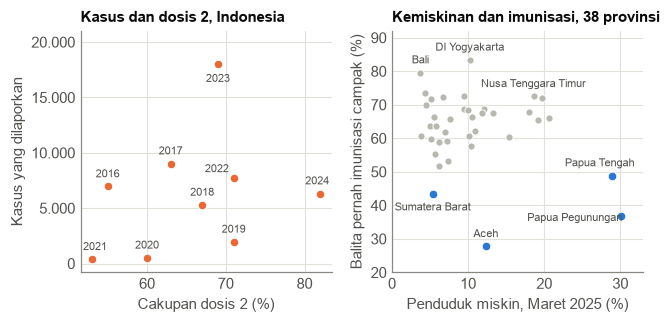

In [17]:
geser_tahun = {
    2016: (0, 6), 2017: (0, 6), 2018: (0, 6), 2019: (0, 6), 2020: (0, 6),
    2021: (2, 6), 2022: (-11, 4), 2023: (0, -12), 2024: (-2, 6),
}
label_provinsi = {
    "Aceh": (0, 6), "Papua Pegunungan": (-30, -3), "Sumatera Barat": (0, -11), "Papua Tengah": (-8, 6),
    "DI Yogyakarta": (0, 6), "Bali": (0, 6), "Nusa Tenggara Timur": (0, 6),
}

fig, (ax_kasus, ax_provinsi) = plt.subplots(1, 2, figsize=(6.6, 2.85), gridspec_kw={"wspace": 0.24})

ax_kasus.scatter(indonesia_kasus["mcv2_wuenic"], indonesia_kasus["kasus_dilaporkan"], s=32, color=ORANYE, edgecolor="white", linewidth=0.7, zorder=3)
for _, baris in indonesia_kasus.iterrows():
    th = int(baris["tahun"])
    ax_kasus.annotate(str(th), (baris["mcv2_wuenic"], baris["kasus_dilaporkan"]), textcoords="offset points", xytext=geser_tahun[th], ha="center", fontsize=7.4, color=INK2)
rapi(ax_kasus)
ax_kasus.set_ylim(-800, 21000)
ax_kasus.set_xlabel("Cakupan dosis 2 (%)")
ax_kasus.set_ylabel("Kasus yang dilaporkan")
ax_kasus.yaxis.set_major_formatter(lambda nilai, _: f"{int(nilai):,}".replace(",", "."))
ax_kasus.set_title("Kasus dan dosis 2, Indonesia", loc="left", fontsize=9.5, fontweight="bold", color=INK)

for _, baris in provinsi.iterrows():
    rendah = baris["imunisasi_campak_pct"] < 50
    ax_provinsi.scatter(baris["persen_miskin_maret_2025"], baris["imunisasi_campak_pct"], s=32 if rendah else 22, color=BIRU if rendah else ABU, edgecolor="white", linewidth=0.6, zorder=3)
    if baris["provinsi"] in label_provinsi:
        ax_provinsi.annotate(baris["provinsi"], (baris["persen_miskin_maret_2025"], baris["imunisasi_campak_pct"]), textcoords="offset points",
                             xytext=label_provinsi[baris["provinsi"]], ha="center", fontsize=7, color=INK2)
rapi(ax_provinsi)
ax_provinsi.set_xlabel("Penduduk miskin, Maret 2025 (%)")
ax_provinsi.set_ylabel("Balita pernah imunisasi campak (%)")
ax_provinsi.set_ylim(20, 92)
ax_provinsi.set_xlim(0, 33)
ax_provinsi.set_title("Kemiskinan dan imunisasi, 38 provinsi", loc="left", fontsize=9.5, fontweight="bold", color=INK)

fig.savefig(GAMBAR / "gambar_3_4_sebar_lain.png")
plt.show()

## 17. Menyimpan hasil

Sel terakhir menyimpan tabel hasil analisis ke `data/hasil/` agar dapat dipakai ulang. Gambar sudah tersimpan di `data/hasil/gambar_makalah/` pada sel sebelumnya.

In [18]:
indonesia[kolom_indonesia].to_csv(HASIL / "makalah_indonesia.csv", index=False)
perbandingan.sort_values("mcv2_2025", ascending=False).to_csv(HASIL / "makalah_asean.csv")
provinsi.to_csv(HASIL / "makalah_provinsi.csv", index=False)
korelasi.to_csv(HASIL / "makalah_korelasi.csv", index=False)
sensitivitas.to_csv(HASIL / "makalah_sensitivitas.csv", index=False)

print("Tabel tersimpan:", ", ".join(sorted(berkas.name for berkas in HASIL.glob("makalah_*.csv"))))
print("Gambar tersimpan:", ", ".join(sorted(berkas.name for berkas in GAMBAR.glob("*.png"))))

Tabel tersimpan: makalah_asean.csv, makalah_indonesia.csv, makalah_korelasi.csv, makalah_provinsi.csv, makalah_sensitivitas.csv
Gambar tersimpan: gambar_3_1_alur.png, gambar_3_2_tren.png, gambar_3_3_sebar_asean.png, gambar_3_4_sebar_lain.png
